# Module 1 - Data Preparation, Summarization and Visualization

## Section 1.1 

### Task 1 (DATASET1) - Opening data and making basic statistics

We first need to import the necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

##### Inspect the structure of the dataset
What kinds of data does it include?

In [2]:
DATASET1 = pd.read_csv("DATASET1.csv")
DATASET1.head()

,ID,civil_status,cancer_family,prostdtfirst,metastasis,date_met,birthdate
0,1,1,1,2017-03-16,0,NaN,1935-01-01
1,2,2,0,2005-03-31,0,NaN,1942-01-01
2,3,2,0,2017-08-08,0,NaN,1959-01-01
3,4,2,0,2008-01-02,0,NaN,1934-02-01
4,5,2,0,2006-05-08,0,NaN,1949-03-01


In [3]:
DATASET1.columns.tolist()

['ID',
 'civil_status',
 'cancer_family',
 'prostdtfirst',
 'metastasis',
 'date_met',
 'birthdate']

##### Which data are numerical and which are categorical? 

We first need to check the way the columns are currently classified.

In [4]:
DATASET1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1159 entries, 0 to 1158
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   ID             1159 non-null   int64 
 1   civil_status   1159 non-null   int64 
 2   cancer_family  1159 non-null   int64 
 3   prostdtfirst   1159 non-null   object
 4   metastasis     1159 non-null   int64 
 5   date_met       421 non-null    object
 6   birthdate      1159 non-null   object
dtypes: int64(4), object(3)
memory usage: 63.5+ KB


##### Which columns should be converted to a different category?
- It makes sense that civil status, history of cancer in the family and the presence of metastasis should be categorical
- It is also logical that the date of cancer diagnosis, the date of metastasis diagnosis and the birthdate should be datetimes

Therefore these columns should be converted accordingly

In [5]:
# Convert categorical variables 
DATASET1["civil_status"] = DATASET1["civil_status"].astype("category") 
DATASET1["cancer_family"] = DATASET1["cancer_family"].astype("category") 
DATASET1["metastasis"] = DATASET1["metastasis"].astype("category") 

# Convert date variables 
DATASET1["prostdtfirst"] = pd.to_datetime(DATASET1["prostdtfirst"], errors="coerce") 
DATASET1["date_met"] = pd.to_datetime(DATASET1["date_met"], errors="coerce") 
DATASET1["birthdate"] = pd.to_datetime(DATASET1["birthdate"], errors="coerce")

In [6]:
DATASET1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1159 entries, 0 to 1158
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             1159 non-null   int64         
 1   civil_status   1159 non-null   category      
 2   cancer_family  1159 non-null   category      
 3   prostdtfirst   1159 non-null   datetime64[ns]
 4   metastasis     1159 non-null   category      
 5   date_met       421 non-null    datetime64[ns]
 6   birthdate      1159 non-null   datetime64[ns]
dtypes: category(3), datetime64[ns](3), int64(1)
memory usage: 40.1 KB


##### Do we have any missing data? Which columns are affected?

We can already from the display of the head that there are values missing from the dataset, particularly in the date of the diagnosis of metastasis. The other columns also need to be checked.

In [7]:
DATASET1.isna().sum()

ID                 0
civil_status       0
cancer_family      0
prostdtfirst       0
metastasis         0
date_met         738
birthdate          0
dtype: int64

In percentage format, that translates to

In [8]:
(DATASET1.isna().mean() * 100).round(2)

ID                0.00
civil_status      0.00
cancer_family     0.00
prostdtfirst      0.00
metastasis        0.00
date_met         63.68
birthdate         0.00
dtype: float64

This is unsurprising. If a patient is not diagnosed with metastasis, it is expected that the value of the diagnosis date would be missing. What needs to be checked now is, how many of the cases with a metastasis diagnosis have a missing diagnosis date.

In [9]:
filtered = DATASET1[(DATASET1['metastasis'] == 1) & (DATASET1['prostdtfirst'].isna())]
filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 0 entries
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             0 non-null      int64         
 1   civil_status   0 non-null      category      
 2   cancer_family  0 non-null      category      
 3   prostdtfirst   0 non-null      datetime64[ns]
 4   metastasis     0 non-null      category      
 5   date_met       0 non-null      datetime64[ns]
 6   birthdate      0 non-null      datetime64[ns]
dtypes: category(3), datetime64[ns](3), int64(1)
memory usage: 372.0 bytes


The filtered dataframe has zero entries, therefore from a semantic standpoint, there are no missing data.

##### How can we summarize the population?

Blah blah blah about population summary

In [10]:
# Compute ages
DATASET1['age_at_diagnosis'] = (
    DATASET1['prostdtfirst'] - DATASET1['birthdate']
).dt.days / 365.25

DATASET1['age_at_metastasis'] = (
    DATASET1['date_met'] - DATASET1['birthdate']
).dt.days / 365.25

# Masks for categorical variables
met_mask = DATASET1['metastasis'] == 1
fam_mask = DATASET1['cancer_family'] == 1
civil1_mask = DATASET1['civil_status'] == 1
civil2_mask = DATASET1['civil_status'] == 2

# Summary table
summary = pd.DataFrame({
    'Variable': [
        'Age at time of PC diagnosis',
        'Age at time of metastasis',
        'Metastasis: Yes',
        'Metastasis: No',
        'Previous cancer in family: Yes',
        'Previous cancer in family: No',
        'Civil status: Married/cohabiting',
        'Civil status: Single/divorced/widow'
    ],
    'Value': [
        # Ages
        f"{DATASET1['age_at_diagnosis'].mean():.1f} ± {DATASET1['age_at_diagnosis'].std():.1f}",
        f"{DATASET1.loc[met_mask, 'age_at_metastasis'].mean():.1f} ± "
        f"{DATASET1.loc[met_mask, 'age_at_metastasis'].std():.1f}",

        # Metastasis
        f"{met_mask.sum()} ({met_mask.mean()*100:.1f}%)",
        f"{(~met_mask).sum()} ({(~met_mask).mean()*100:.1f}%)",

        # Family cancer (fixed)
        f"{fam_mask.sum()} ({fam_mask.mean()*100:.1f}%)",
        f"{(~fam_mask).sum()} ({(~fam_mask).mean()*100:.1f}%)",

        # Civil status
        f"{civil1_mask.sum()} ({civil1_mask.mean()*100:.1f}%)",
        f"{civil2_mask.sum()} ({civil2_mask.mean()*100:.1f}%)"
    ]
})

summary

,Variable,Value
0,Age at time of PC diagnosis,74.3 ± 8.7
1,Age at time of metastasis,78.9 ± 8.5
2,Metastasis: Yes,421 (36.3%)
3,Metastasis: No,738 (63.7%)
4,Previous cancer in family: Yes,623 (53.8%)
5,Previous cancer in family: No,536 (46.2%)
6,Civil status: Married/cohabiting,808 (69.7%)
7,Civil status: Single/divorced/widow,351 (30.3%)


Some more blah blah about summary, and the results and what it means and blah blah blah

### Task 2 (DATASET2) - Inspecting Biochemical Data

Similarly to the previous task, we first import and then inspect the structure of the data.

In [11]:
DATASET2 = pd.read_csv("DATASET2.csv")
DATASET2.head()

,ID,monocyte,urea,lymphocyte,thrombocyte,erythrocyte,albumin,creatinine,globulin,psa,coag_factor
0,1,46.14,2.90,53.0,64.0,93.0,6.60,0.30,6.44,173.00,9.66
1,2,50.14,1.53,59.0,50.0,46.0,2.48,0.15,1.84,0.10,7.65
2,3,49.86,1.28,NaN,76.0,108.6,11.96,0.17,5.27,7.50,0.08
3,4,49.57,1.56,57.0,60.0,83.2,6.41,0.24,5.03,0.35,7.26
4,5,57.00,1.69,NaN,112.0,178.4,6.05,0.11,2.95,3.60,1.51


##### Which data are numerical and which are categorical? 

Again, we check the way the columns are currently classified, and make the necessary conversions

In [12]:
DATASET2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1159 entries, 0 to 1158
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           1159 non-null   int64  
 1   monocyte     1137 non-null   float64
 2   urea         1109 non-null   float64
 3   lymphocyte   996 non-null    float64
 4   thrombocyte  1138 non-null   float64
 5   erythrocyte  1072 non-null   float64
 6   albumin      1091 non-null   float64
 7   creatinine   1066 non-null   float64
 8   globulin     1156 non-null   float64
 9   psa          1159 non-null   float64
 10  coag_factor  1131 non-null   float64
dtypes: float64(10), int64(1)
memory usage: 99.7 KB


The data types seem to make sense, therefore we do not make any conversions.

##### Are there any missing data? In what percentages?

Taking into consideration that these are results from laboratory exams, it makes sense that there would be missing values, since not every substance gets checked in all the examinations (some of them might not be necessary for the purpose of the exam, so they would be skipped).

In [13]:
DATASET2.isna().sum()

ID               0
monocyte        22
urea            50
lymphocyte     163
thrombocyte     21
erythrocyte     87
albumin         68
creatinine      93
globulin         3
psa              0
coag_factor     28
dtype: int64

In [14]:
(DATASET2.isna().mean() * 100).round(2)

ID              0.00
monocyte        1.90
urea            4.31
lymphocyte     14.06
thrombocyte     1.81
erythrocyte     7.51
albumin         5.87
creatinine      8.02
globulin        0.26
psa             0.00
coag_factor     2.42
dtype: float64

##### Visualization of the missing data

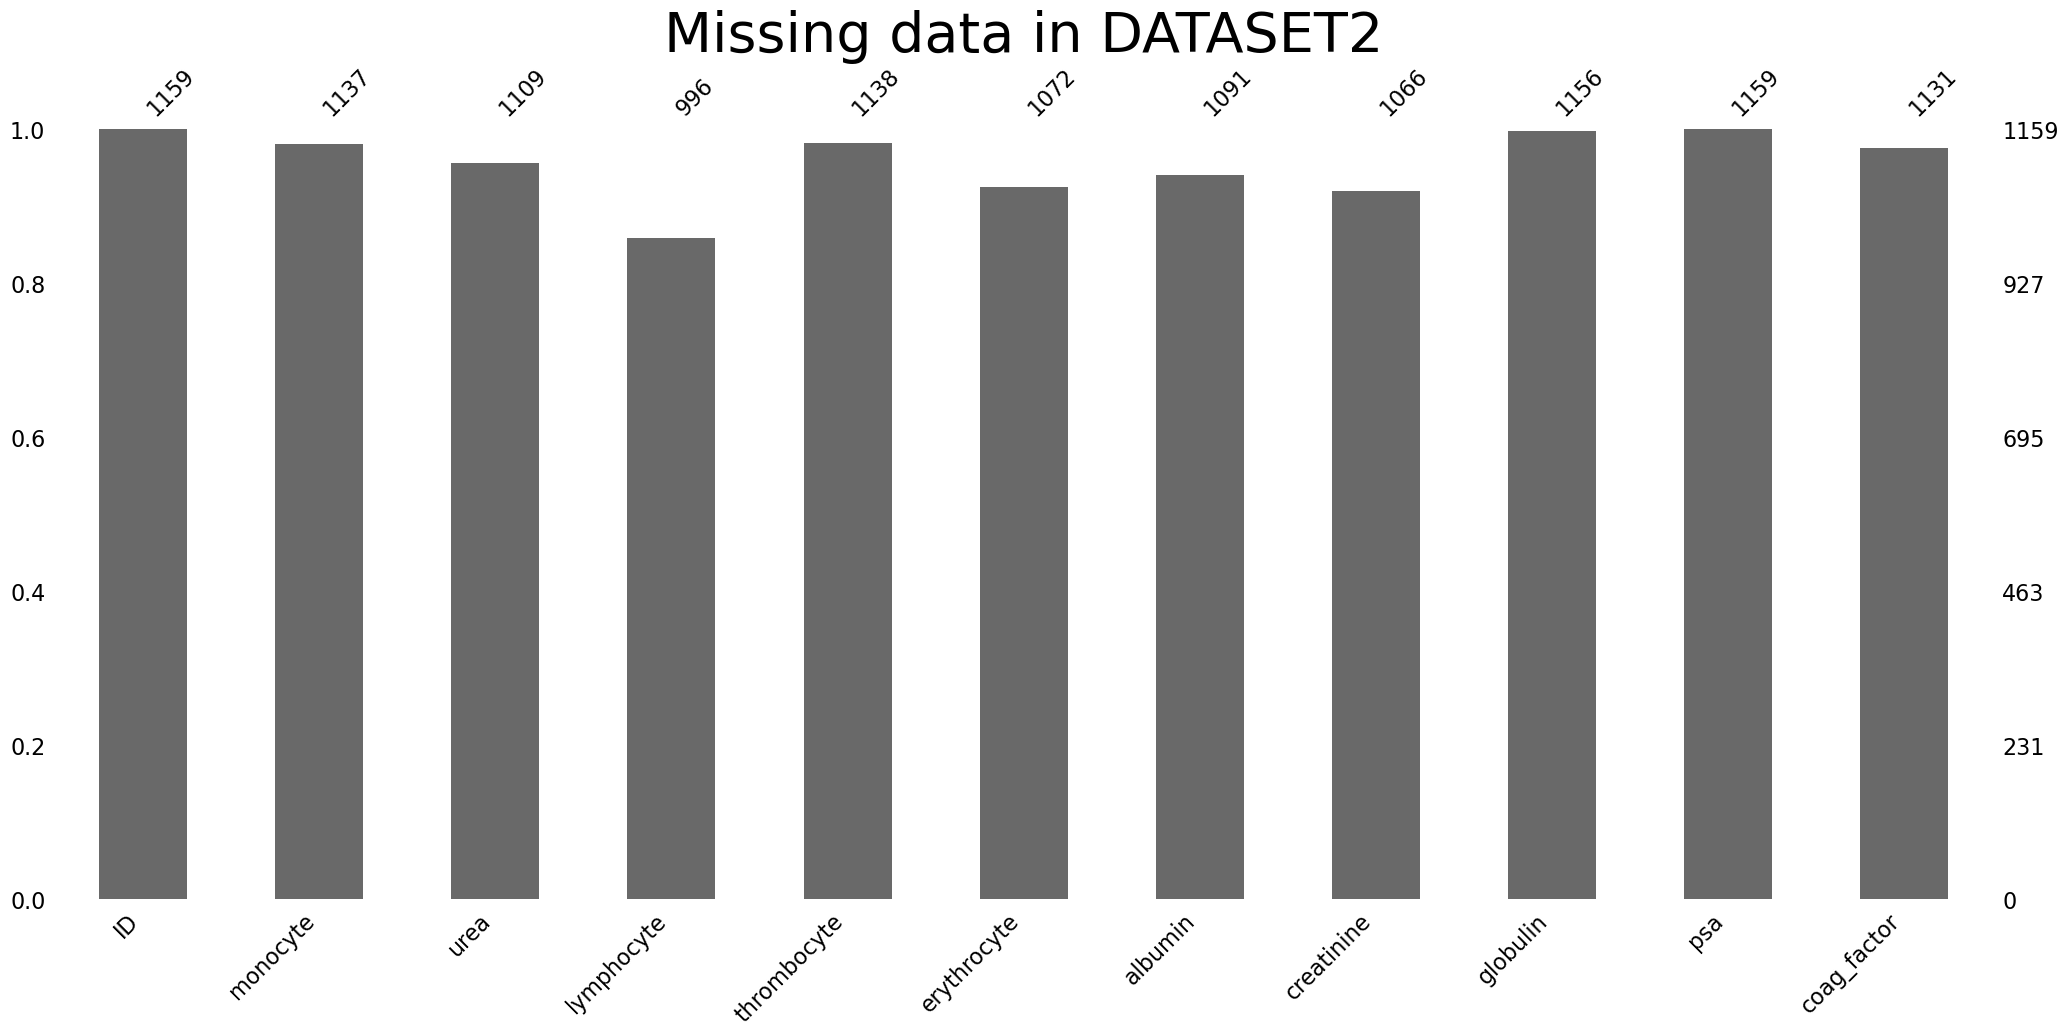

In [15]:
msno.bar(DATASET2) 
plt.title("Missing data in DATASET2", fontsize=40) 
plt.show()

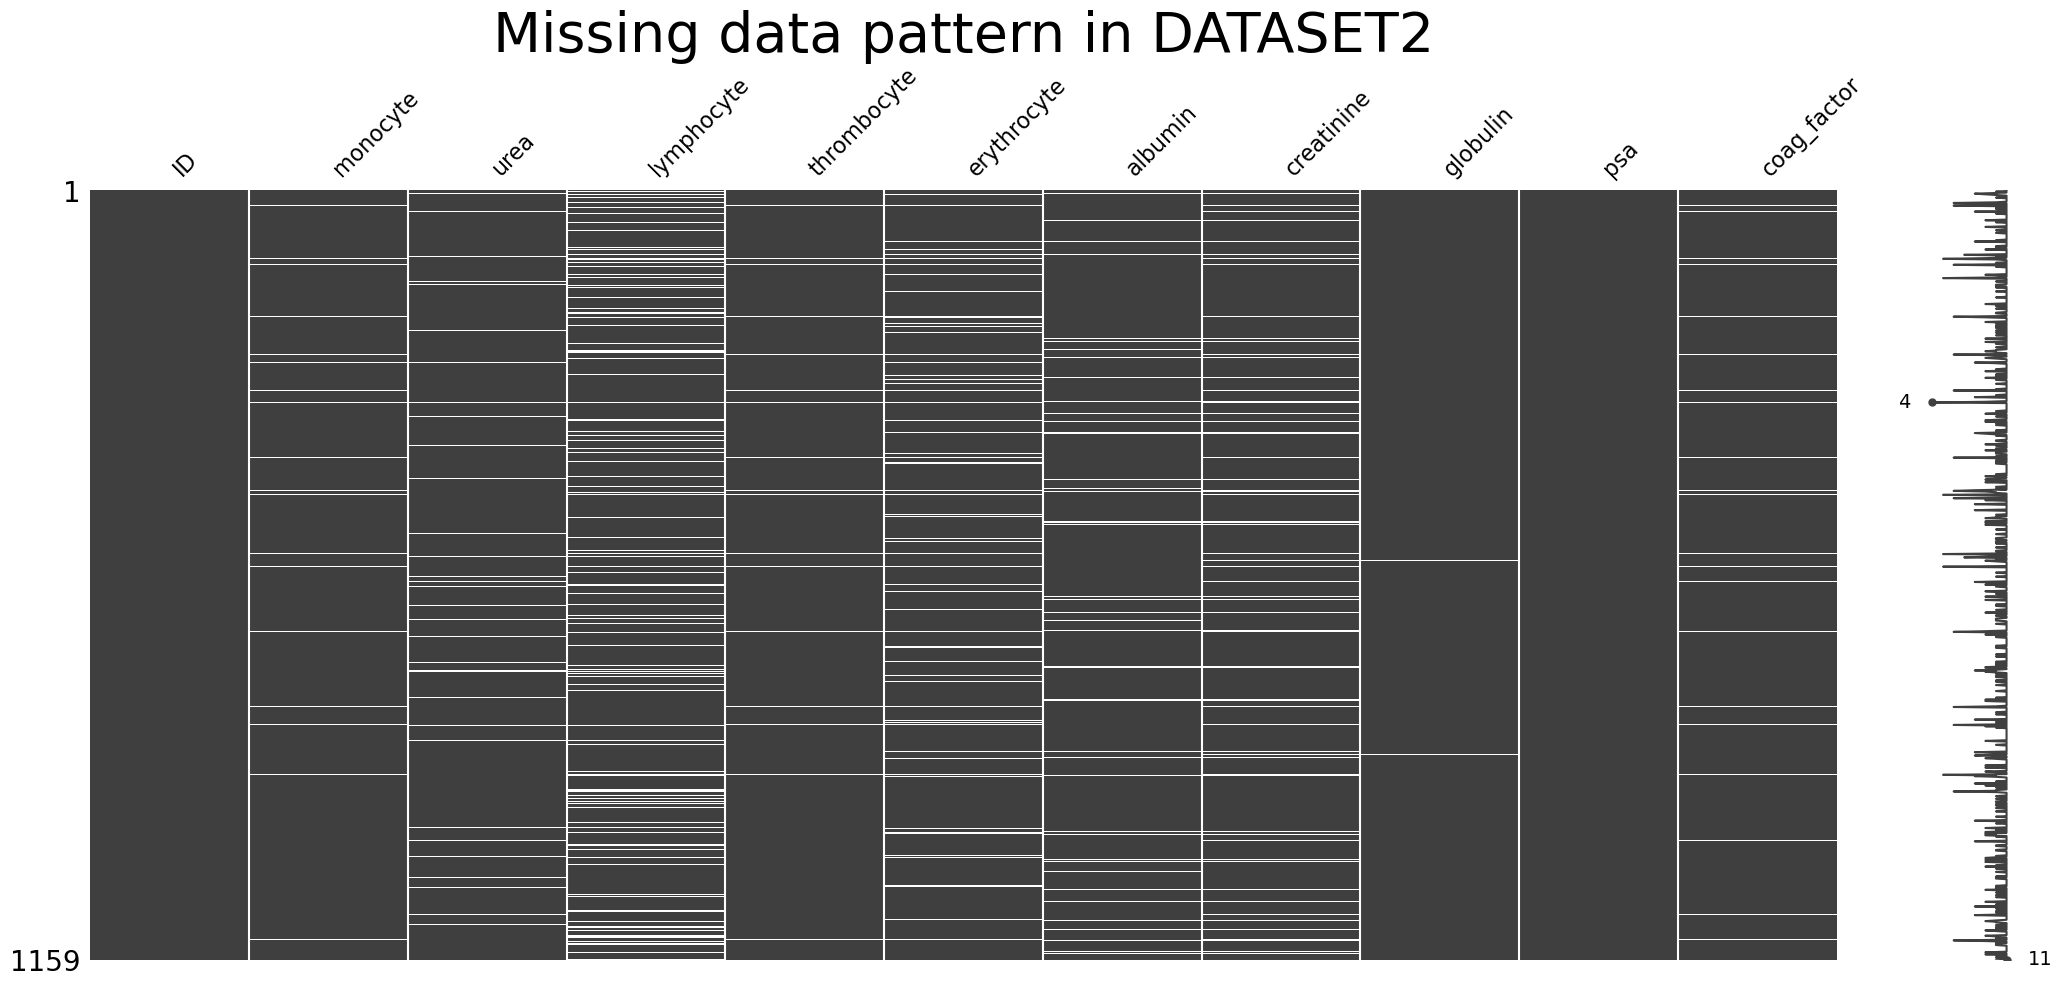

In [16]:
msno.matrix(DATASET2) 
plt.title("Missing data pattern in DATASET2", fontsize=40) 
plt.show()

The missing‑data matrix reveals that DATASET2 is largely complete, with most variables showing minimal missingness. A few variables contain isolated gaps scattered across individual observations, suggesting that missing values are randomly distributed rather than concentrated in specific patient groups, while no variable displays a block‑like pattern of missingness, which would indicate systematic absence (e.g., missing for all early or late records). The accompanying bar plot confirms that only a small number of variables have non‑negligible missing counts, but even these remain modest relative to the full sample size. Overall the dataset appears to be suitable for standard imputation approaches or complete‑case analyses without major risk of bias.

##### Correlation Matrix for biochemical variables

We represent the correlation between the biochemical variables using a heatmap

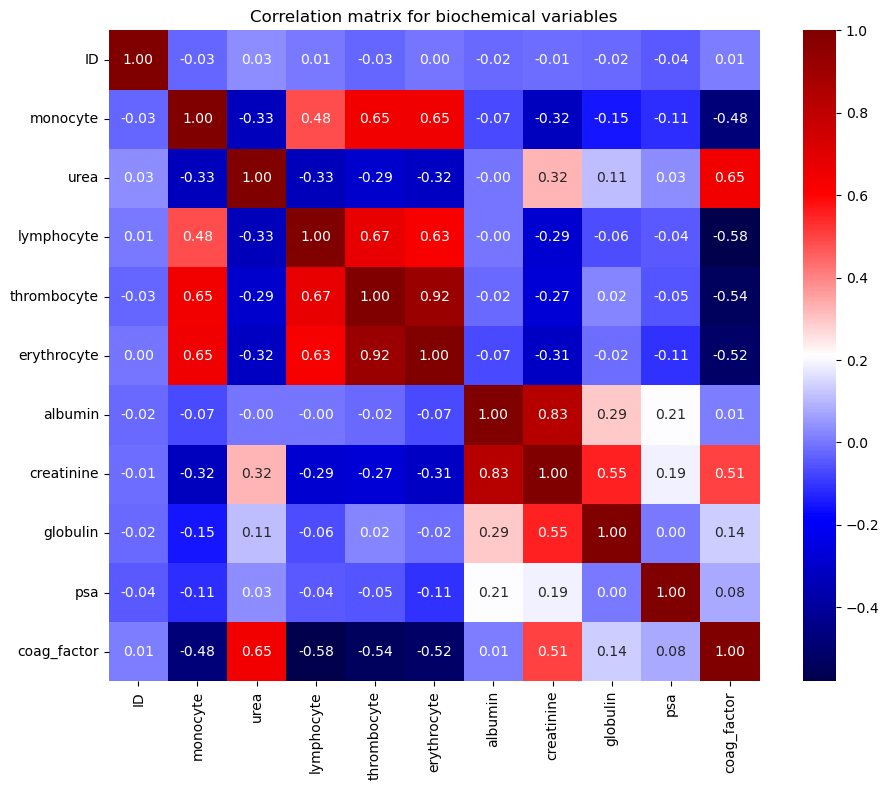

In [17]:
num_dataset2 = DATASET2.select_dtypes(include=["number"]) 
corr_matrix = num_dataset2.corr() 
plt.figure(figsize=(10, 8)) 
sns.heatmap(corr_matrix, cmap='seismic', annot=True, fmt=".2f", square=True)
plt.title("Correlation matrix for biochemical variables") 
plt.tight_layout() 
plt.show()

The correlation matrix illustrates the degree to which the biochemical variables in DATASET2 co‑vary, revealing a generally modest pattern of linear associations. Most pairwise correlations cluster around zero, indicating that the majority of variables behave largely independently of one another. A few moderate correlations are visible, suggesting biologically plausible relationships — for example, parameters linked to hematologic or renal function show mild positive or negative associations, though none approach the strength typically required to imply redundancy or multicollinearity. Importantly, the absence of strong correlations (i.e., values approaching ±1) suggests that the dataset does not contain highly collinear predictors, and thus each variable contributes distinct informational value. Overall, the correlation structure supports the use of these variables in multivariable analyses without substantial risk of instability due to interdependence.

### Task 3 (DATASET3) - Opening data and making basic statistics

Similarly to the previous task, we first import and then inspect the structure of the data.

In [18]:
DATASET3 = pd.read_csv("DATASET3.csv") 
DATASET3.head() 

,ID,code,date_diag
0,1,DE119,2007-10-22
1,1,DM819,2014-09-22
2,3,DM819,2014-09-08
3,6,DI109,2009-10-16
4,6,DE119,2010-02-03


In [19]:
DATASET3.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1208 entries, 0 to 1207
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         1208 non-null   int64 
 1   code       1208 non-null   object
 2   date_diag  1208 non-null   object
dtypes: int64(1), object(2)
memory usage: 28.4+ KB


In [20]:
DATASET3["code"].value_counts()

code
DR339    293
DM819    262
DH911    181
DI109    173
DE119    157
DE780    142
Name: count, dtype: int64

##### Which diseases do the codes correspond to?

We create another column with the corresponding disease

In [21]:
code_to_disease = { 
    "DE119": "diabetes", 
    "DH911": "hearing_loss", 
    "DE780": "hypercholesterolaemia", 
    "DI109": "hypertension", 
    "DM819": "osteoporosis", 
    "DR339": "urinary_retention" } 

DATASET3["disease"] = DATASET3["code"].map(code_to_disease).fillna("other")

In [22]:
DATASET3

,ID,code,date_diag,disease
0,1,DE119,2007-10-22,diabetes
1,1,DM819,2014-09-22,osteoporosis
2,3,DM819,2014-09-08,osteoporosis
3,6,DI109,2009-10-16,hypertension
4,6,DE119,2010-02-03,diabetes
...,...,...,...,...
1203,1153,DR339,2007-01-24,urinary_retention
1204,1153,DM819,2012-02-06,osteoporosis
1205,1154,DR339,2017-02-08,urinary_retention
1206,1155,DH911,2015-08-07,hearing_loss


##### How can the data be reshaped?

We could further reshape the data by creating binary variables for each disease and transform the data so it has one row per patient.

In [23]:
DATASET3["diag"] = 1 
DISEASES_WIDE = ( 
    DATASET3 .pivot_table(index="ID", columns="disease", values="diag", aggfunc="max", fill_value=0) .reset_index() 
) 
DISEASES_WIDE.head()

disease,ID,diabetes,hearing_loss,hypercholesterolaemia,hypertension,osteoporosis,urinary_retention
0,1,1,0,0,0,1,0
1,3,0,0,0,0,1,0
2,6,1,0,0,1,0,0
3,7,0,0,0,0,0,1
4,8,0,0,0,0,0,1


### TASK 4 (DATASET 1–3) – Merging the data

For the purpose of collecting all the available information of the patients together, we merge the three datasets into a complete, larger one.

In [24]:
DATASET123 = pd.merge(DATASET1, DATASET2, on="ID", how="left") 
DATASET123 = pd.merge(DATASET123, DISEASES_WIDE, on="ID", how="left")
DATASET123.head()

,ID,civil_status,cancer_family,prostdtfirst,metastasis,date_met,birthdate,age_at_diagnosis,age_at_metastasis,monocyte,...,creatinine,globulin,psa,coag_factor,diabetes,hearing_loss,hypercholesterolaemia,hypertension,osteoporosis,urinary_retention
0,1,1,1,2017-03-16,0,NaT,1935-01-01,82.203970,NaN,46.14,...,0.30,6.44,173.00,9.66,1.0,0.0,0.0,0.0,1.0,0.0
1,2,2,0,2005-03-31,0,NaT,1942-01-01,63.244353,NaN,50.14,...,0.15,1.84,0.10,7.65,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2,0,2017-08-08,0,NaT,1959-01-01,58.600958,NaN,49.86,...,0.17,5.27,7.50,0.08,0.0,0.0,0.0,0.0,1.0,0.0
3,4,2,0,2008-01-02,0,NaT,1934-02-01,73.916496,NaN,49.57,...,0.24,5.03,0.35,7.26,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2,0,2006-05-08,0,NaT,1949-03-01,57.185489,NaN,57.00,...,0.11,2.95,3.60,1.51,NaN,NaN,NaN,NaN,NaN,NaN


We further transform it by changing the NaN values from the disease columns to zero.

In [25]:
disease_cols = [ "diabetes", "hearing_loss", "hypercholesterolaemia", "hypertension", "osteoporosis", "urinary_retention" ] 
present_disease_cols = [col for col in disease_cols if col in DATASET123.columns] 
DATASET123[present_disease_cols] = DATASET123[present_disease_cols].fillna(0).astype(int)

DATASET123.head()

,ID,civil_status,cancer_family,prostdtfirst,metastasis,date_met,birthdate,age_at_diagnosis,age_at_metastasis,monocyte,...,creatinine,globulin,psa,coag_factor,diabetes,hearing_loss,hypercholesterolaemia,hypertension,osteoporosis,urinary_retention
0,1,1,1,2017-03-16,0,NaT,1935-01-01,82.203970,NaN,46.14,...,0.30,6.44,173.00,9.66,1,0,0,0,1,0
1,2,2,0,2005-03-31,0,NaT,1942-01-01,63.244353,NaN,50.14,...,0.15,1.84,0.10,7.65,0,0,0,0,0,0
2,3,2,0,2017-08-08,0,NaT,1959-01-01,58.600958,NaN,49.86,...,0.17,5.27,7.50,0.08,0,0,0,0,1,0
3,4,2,0,2008-01-02,0,NaT,1934-02-01,73.916496,NaN,49.57,...,0.24,5.03,0.35,7.26,0,0,0,0,0,0
4,5,2,0,2006-05-08,0,NaT,1949-03-01,57.185489,NaN,57.00,...,0.11,2.95,3.60,1.51,0,0,0,0,0,0


We check if the column types for all the columns make sense, and if not, we change them accordingly. For instance, 

In [26]:
DATASET123.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1159 entries, 0 to 1158
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ID                     1159 non-null   int64         
 1   civil_status           1159 non-null   category      
 2   cancer_family          1159 non-null   category      
 3   prostdtfirst           1159 non-null   datetime64[ns]
 4   metastasis             1159 non-null   category      
 5   date_met               421 non-null    datetime64[ns]
 6   birthdate              1159 non-null   datetime64[ns]
 7   age_at_diagnosis       1159 non-null   float64       
 8   age_at_metastasis      421 non-null    float64       
 9   monocyte               1137 non-null   float64       
 10  urea                   1109 non-null   float64       
 11  lymphocyte             996 non-null    float64       
 12  thrombocyte            1138 non-null   float64       
 13  ery

##### Missing value substitution: Mean or Median?

The two available methods for missing value substitution are using the mean and the median, both of which have their strengths and weaknesses.

- Mean imputation is easy to compute and preserves the overall average of the variable, but is also highly sensitive to outliers and may distort relationships between variables. Its use is typically suggested the data is approximately normally distributed with few or no outliers
- Median imputation is robust to outliers and skewed distributions and better represents the 'typical value' in skewed data but the mean is not preserved and the shape of the distribution is changed.

In order to see which one would be more fitting we have a look at the distributions of the biochemical data, by constructing the respective histograms.

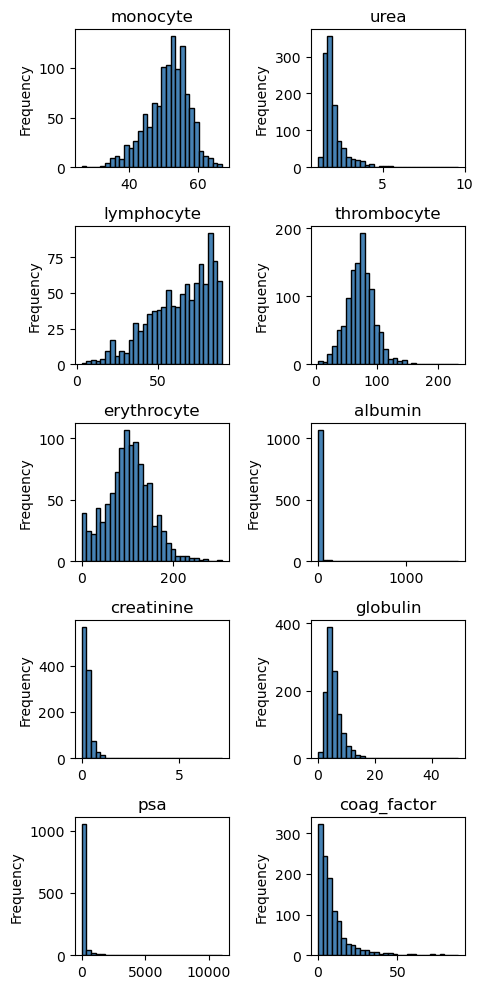

In [27]:
biochemical_data = ['monocyte', 'urea', 'lymphocyte', 'thrombocyte', 'erythrocyte', 'albumin', 'creatinine', 'globulin', 'psa', 'coag_factor']

fig, axes = plt.subplots(5, 2, figsize=(5, 10))
axes = axes.flatten()

for ax, col in zip(axes, biochemical_data):
    ax.hist(DATASET2[col].dropna(), bins=30, color='steelblue', edgecolor='black')
    ax.set_title(col, fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel('Frequency')

# Hide any unused subplots (since we have 10 variables but 12 slots)
for ax in axes[len(biochemical_data):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

Most of the histograms appear skewed and present outliers, with the expections being thrombocyte and erythrocyte, whose distributions appear quite balanced and symmetrical. Therefore, we choose to impute missing values with the median, as this is most suitable for the majority of the biochemical markers.

In [28]:
# Example: loop over several numerical variables 
for col in biochemical_data: 
    if col in DATASET123.columns: 
        DATASET123[col] = DATASET123[col].fillna(DATASET123[col].mean())
        
# Inspect the data again to see if the missing values have been handled
DATASET123.isna().sum().sort_values(ascending=False)

date_met                 738
age_at_metastasis        738
ID                         0
albumin                    0
osteoporosis               0
hypertension               0
hypercholesterolaemia      0
hearing_loss               0
diabetes                   0
coag_factor                0
psa                        0
globulin                   0
creatinine                 0
thrombocyte                0
erythrocyte                0
civil_status               0
lymphocyte                 0
urea                       0
monocyte                   0
age_at_diagnosis           0
birthdate                  0
metastasis                 0
prostdtfirst               0
cancer_family              0
urinary_retention          0
dtype: int64

Missing values handled!

##### Export the final csv 

In [29]:
DATASET123.to_csv("DATASET123.csv", index=False)

## Section 1.2

### Task 1 - Measures of test performance based on PSA

In [32]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.metrics import roc_curve 
from sklearn.metrics import roc_auc_score 
from sklearn.preprocessing import StandardScaler 
from sklearn.decomposition import PCA

In [30]:
DATASET123 = pd.read_csv("DATASET123.csv") 
DATASET123.head()

,ID,civil_status,cancer_family,prostdtfirst,metastasis,date_met,birthdate,age_at_diagnosis,age_at_metastasis,monocyte,...,creatinine,globulin,psa,coag_factor,diabetes,hearing_loss,hypercholesterolaemia,hypertension,osteoporosis,urinary_retention
0,1,1,1,2017-03-16,0,NaN,1935-01-01,82.203970,NaN,46.14,...,0.30,6.44,173.00,9.66,1,0,0,0,1,0
1,2,2,0,2005-03-31,0,NaN,1942-01-01,63.244353,NaN,50.14,...,0.15,1.84,0.10,7.65,0,0,0,0,0,0
2,3,2,0,2017-08-08,0,NaN,1959-01-01,58.600958,NaN,49.86,...,0.17,5.27,7.50,0.08,0,0,0,0,1,0
3,4,2,0,2008-01-02,0,NaN,1934-02-01,73.916496,NaN,49.57,...,0.24,5.03,0.35,7.26,0,0,0,0,0,0
4,5,2,0,2006-05-08,0,NaN,1949-03-01,57.185489,NaN,57.00,...,0.11,2.95,3.60,1.51,0,0,0,0,0,0


In [31]:
DATASET123["test_result100"] = np.where( DATASET123["psa"] > 100, 1, 0 )
DATASET123["test_result20"] = np.where(DATASET123["psa"] > 20, 1, 0)

DATASET123.head()

,ID,civil_status,cancer_family,prostdtfirst,metastasis,date_met,birthdate,age_at_diagnosis,age_at_metastasis,monocyte,...,psa,coag_factor,diabetes,hearing_loss,hypercholesterolaemia,hypertension,osteoporosis,urinary_retention,test_result100,test_result20
0,1,1,1,2017-03-16,0,NaN,1935-01-01,82.203970,NaN,46.14,...,173.00,9.66,1,0,0,0,1,0,1,1
1,2,2,0,2005-03-31,0,NaN,1942-01-01,63.244353,NaN,50.14,...,0.10,7.65,0,0,0,0,0,0,0,0
2,3,2,0,2017-08-08,0,NaN,1959-01-01,58.600958,NaN,49.86,...,7.50,0.08,0,0,0,0,1,0,0,0
3,4,2,0,2008-01-02,0,NaN,1934-02-01,73.916496,NaN,49.57,...,0.35,7.26,0,0,0,0,0,0,0,0
4,5,2,0,2006-05-08,0,NaN,1949-03-01,57.185489,NaN,57.00,...,3.60,1.51,0,0,0,0,0,0,0,0


In [32]:
def compute_metrics(df, truth_col, test_col):
    TP = ((df[truth_col] == 1) & (df[test_col] == 1)).sum()
    TN = ((df[truth_col] == 0) & (df[test_col] == 0)).sum()
    FP = ((df[truth_col] == 0) & (df[test_col] == 1)).sum()
    FN = ((df[truth_col] == 1) & (df[test_col] == 0)).sum()

    sensitivity = TP / (TP + FN) if (TP + FN) > 0 else np.nan
    specificity = TN / (TN + FP) if (TN + FP) > 0 else np.nan
    accuracy = (TP + TN) / (TP + TN + FP + FN)

    return TP, TN, FP, FN, sensitivity, specificity, accuracy

TP20, TN20, FP20, FN20, sens20, spec20, acc20 = compute_metrics(DATASET123, "metastasis", "test_result20")
TP100, TN100, FP100, FN100, sens100, spec100, acc100 = compute_metrics(DATASET123, "metastasis", "test_result100")

summary = pd.DataFrame({
    "Metric": ["Sensitivity", "Specificity", "Accuracy"],
    "PSA > 20 ng/mL": [sens20, spec20, acc20],
    "PSA > 100 ng/mL": [sens100, spec100, acc100]
})

summary

,Metric,PSA > 20 ng/mL,PSA > 100 ng/mL
0,Sensitivity,0.596200,0.323040
1,Specificity,0.672087,0.867209
2,Accuracy,0.644521,0.669543


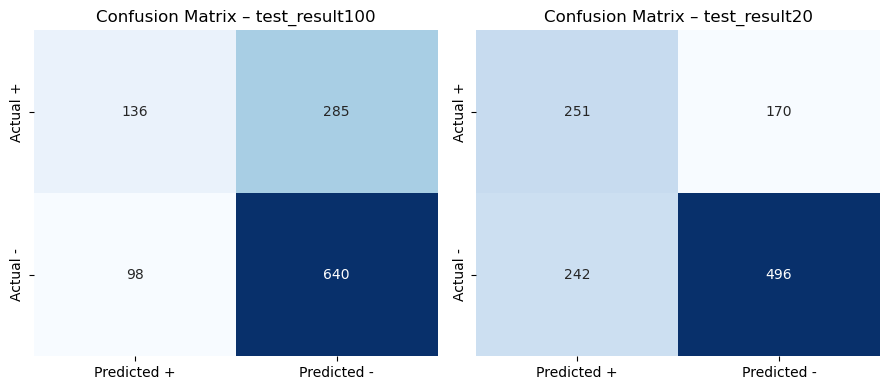

In [33]:
# True Positives (metastasis = 1 AND test positive)
TP = ((DATASET123["metastasis"] == 1) & (DATASET123["test_result100"] == 1)).sum()

# False Positives (metastasis = 0 AND test positive)
FP = ((DATASET123["metastasis"] == 0) & (DATASET123["test_result100"] == 1)).sum()

# False Negatives (metastasis = 1 AND test negative)
FN = ((DATASET123["metastasis"] == 1) & (DATASET123["test_result100"] == 0)).sum()

# True Negatives (metastasis = 0 AND test negative)
TN = ((DATASET123["metastasis"] == 0) & (DATASET123["test_result100"] == 0)).sum()

# Build confusion matrix as a 2×2 array
conf_matrix1 = np.array([[TP, FN],
                        [FP, TN]])
# True Positives (metastasis = 1 AND test positive)
TP = ((DATASET123["metastasis"] == 1) & (DATASET123["test_result20"] == 1)).sum()

# False Positives (metastasis = 0 AND test positive)
FP = ((DATASET123["metastasis"] == 0) & (DATASET123["test_result20"] == 1)).sum()

# False Negatives (metastasis = 1 AND test negative)
FN = ((DATASET123["metastasis"] == 1) & (DATASET123["test_result20"] == 0)).sum()

# True Negatives (metastasis = 0 AND test negative)
TN = ((DATASET123["metastasis"] == 0) & (DATASET123["test_result20"] == 0)).sum()

conf_matrix2 = np.array([[TP, FN], [FP, TN]])

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
# Titles for each matrix
titles = ["Confusion Matrix – test_result100", "Confusion Matrix – test_result20"]
# Plot each heatmap
for ax, cm, title in zip(axes, [conf_matrix1, conf_matrix2], titles):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Predicted +", "Predicted -"],
                yticklabels=["Actual +", "Actual -"],
                ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

### Task 3 - Using the ROC curve to find the optimal cutoff